# Аналитика подписочного VPN через HAPP

Воспроизводимый анализ синтетического сервиса `ShieldRoute`: продажи через сайт и Telegram-бот, выдача ссылки подписки, её загрузка в HAPP и использование прокси.

## Краткий вывод

- Стабильное платящее ядро — **435** пользователей в каждом полном месяце; новые и временные пользователи считаются сверх него.
- Всего активных платящих пользователей по месяцам: **442–508**.
- Среди **214** новых оплаченных подписок полная 7-дневная активация — **55,1%**, загрузка ссылки в HAPP — **89,3%**.
- Активация по каналу продажи: Telegram-бот **58,6%**, сайт **49,4%**. Это описательное сравнение.

## Контекст и метод

Путь пользователя: **сайт / Telegram-бот → оплата → персональная ссылка → HAPP → прокси-сессии**. Собственного клиентского приложения у сервиса нет.

Подписка активирована за 7 дней, если ссылка загружена в HAPP, проведено не менее трёх успешных прокси-сессий в два разных UTC-дня и накоплено не менее 30 минут защищённого трафика.

Стабильное ядро — пользователи, чья подписка началась до периода наблюдения и оставалась активной до его конца. Все данные и результаты синтетические.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from vpn_analytics.data_quality import validate_dataset
from vpn_analytics.metrics import monthly_business_records, subscriber_activation_records

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "generated"
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {"base": "#173F5F", "total": "#F2A900", "accent": "#2A9D8F"}

## Данные и контроль качества

In [2]:
manifest = json.loads((DATA_DIR / "manifest.json").read_text(encoding="utf-8"))
quality = pd.DataFrame(
    [{"check": item.check_name, "failures": item.failure_count, "status": item.status} for item in validate_dataset(DATA_DIR)]
)
assert quality["failures"].sum() == 0
display(pd.Series(manifest["counts"], name="rows").to_frame())
display(quality)

,rows
dataset_periods,1
payments,2056
proxy_servers,18
proxy_sessions,33819
subscription_links,649
subscriptions,649
users,800


,check,failures,status
0,one_dataset_period,0,PASS
1,unique_user_id,0,PASS
2,unique_subscription_id,0,PASS
3,unique_subscription_link_id,0,PASS
4,unique_payment_id,0,PASS
5,unique_server_id,0,PASS
6,unique_proxy_session_id,0,PASS
7,subscriptions_have_users,0,PASS
8,one_subscription_per_user,0,PASS
9,one_link_per_subscription,0,PASS


In [3]:
activation = pd.DataFrame(subscriber_activation_records(DATA_DIR))
monthly = pd.DataFrame(monthly_business_records(DATA_DIR))
activation["link_fetched_7d"] = activation["first_link_fetched_at"].notna() & (
    activation["first_link_fetched_at"]
    < activation["subscription_started_at"] + pd.to_timedelta(7, unit="D")
)
monthly["month"] = pd.to_datetime(monthly["month_start"]).dt.strftime("%b %Y")
activation.head(3)

,user_id,subscription_id,registered_at,acquisition_channel,country,signup_source,sales_channel,plan,price_rub,purchased_at,...,protected_minutes_7d,traffic_gb_7d,failed_attempts_7d,total_attempts_7d,failure_rate_7d,p95_connection_time_ms,forced_disconnect_rate_7d,time_to_first_value_hours,activated_7d,link_fetched_7d
0,usr_000439,sub_000439,2026-06-09 19:30:20+00:00,referral,RU,telegram_bot,telegram_bot,three_months,899.0,2026-06-10 18:08:03.486900+00:00,...,197.548132,37.094114,0,4,0.0,1069.1,0.25,13.923875,True,True
1,usr_000440,sub_000440,2026-04-01 00:00:06+00:00,referral,RU,telegram_bot,telegram_bot,one_month,349.0,2026-04-02 16:09:04.714366+00:00,...,349.272712,62.720965,0,10,0.0,2782.2,0.10,16.935158,True,True
2,usr_000442,sub_000442,2026-04-13 10:30:01+00:00,referral,RU,telegram_bot,telegram_bot,twelve_months,2990.0,2026-04-14 20:10:50.158635+00:00,...,0.000000,0.000000,1,1,1.0,NaN,NaN,NaN,False,True


## Результаты

In [4]:
link = activation["link_fetched_7d"]
success = activation["first_successful_connection_at"].notna()
funnel = pd.Series({
    "Оплачено": len(activation),
    "Ссылка загружена в HAPP": link.sum(),
    "Есть успешное подключение": (link & success).sum(),
    "3+ успешных сессии": (link & activation["successful_sessions_7d"].ge(3)).sum(),
    "Также 2+ активных дня": (link & activation["successful_sessions_7d"].ge(3) & activation["active_days_7d"].ge(2)).sum(),
    "Активация за 7 дней": activation["activated_7d"].sum(),
}, name="subscriptions").to_frame()
funnel["share_of_paid"] = funnel["subscriptions"] / len(activation)
funnel

,subscriptions,share_of_paid
Оплачено,214,1.000000
Ссылка загружена в HAPP,191,0.892523
Есть успешное подключение,168,0.785047
3+ успешных сессии,118,0.551402
Также 2+ активных дня,118,0.551402
Активация за 7 дней,118,0.551402


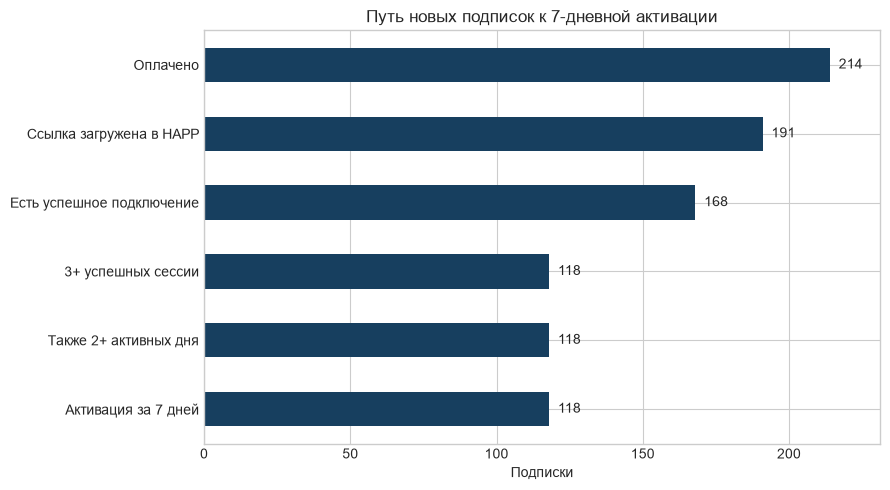

In [5]:
ax = funnel.iloc[::-1]["subscriptions"].plot.barh(figsize=(9, 5), color=COLORS["base"])
ax.set(title="Путь новых подписок к 7-дневной активации", xlabel="Подписки", ylabel="")
ax.set_xlim(0, len(activation) * 1.08)
for bar in ax.patches:
    ax.text(bar.get_width() + 3, bar.get_y() + bar.get_height() / 2, f"{bar.get_width():.0f}", va="center")
plt.tight_layout();

In [6]:
monthly_view = monthly[[
    "month", "active_paid_subscribers", "monthly_active_paid_users",
    "regular_paid_users", "new_paid_users", "churned_users",
    "cash_revenue_rub", "normalized_mrr_rub", "connection_failure_rate", "traffic_gb",
]].copy()
monthly_view

,month,active_paid_subscribers,monthly_active_paid_users,regular_paid_users,new_paid_users,churned_users,cash_revenue_rub,normalized_mrr_rub,connection_failure_rate,traffic_gb
0,Jan 2026,447,442,435,12,0,138778.0,144438.333333,0.041636,30887.350746
1,Feb 2026,468,455,435,21,9,144484.0,148329.166667,0.046261,31094.018070
2,Mar 2026,499,474,435,40,16,170906.0,155959.333333,0.046819,31821.010169
3,Apr 2026,546,508,435,63,33,198451.0,165635.333333,0.043552,33393.759488
4,May 2026,538,489,435,25,52,164663.0,155911.666667,0.037633,31693.048035
5,Jun 2026,539,507,435,53,24,161998.0,165786.000000,0.050446,32389.815955


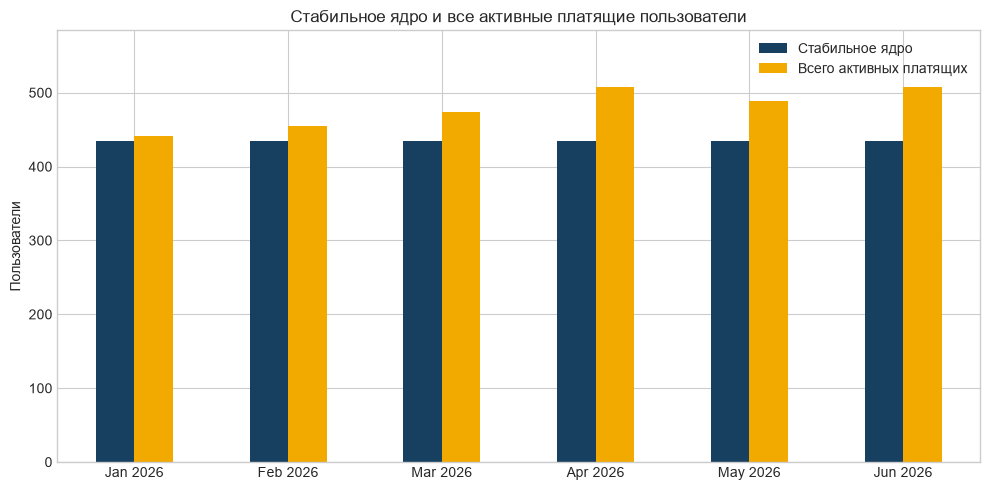

In [7]:
ax = monthly.set_index("month")[["regular_paid_users", "monthly_active_paid_users"]].plot(
    kind="bar", figsize=(10, 5), color=[COLORS["base"], COLORS["total"]]
)
ax.set(title="Стабильное ядро и все активные платящие пользователи", xlabel="", ylabel="Пользователи")
ax.legend(["Стабильное ядро", "Всего активных платящих"])
ax.set_ylim(0, monthly["monthly_active_paid_users"].max() * 1.15)
plt.xticks(rotation=0)
plt.tight_layout();

In [8]:
channels = activation.groupby("sales_channel").agg(
    paid_subscriptions=("subscription_id", "size"),
    link_fetch_rate=("link_fetched_7d", "mean"),
    activation_rate=("activated_7d", "mean"),
).sort_values("activation_rate", ascending=False)
channels

,paid_subscriptions,link_fetch_rate,activation_rate
sales_channel,,,
telegram_bot,133,0.909774,0.586466
website,81,0.864198,0.493827


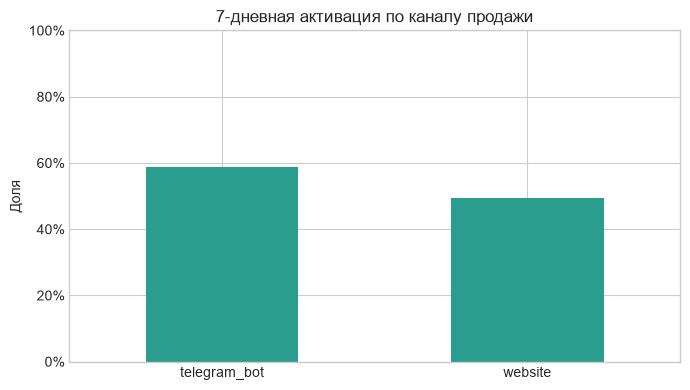

In [9]:
ax = channels["activation_rate"].plot.bar(figsize=(7, 4), color=COLORS["accent"])
ax.set(title="7-дневная активация по каналу продажи", xlabel="", ylabel="Доля")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
plt.xticks(rotation=0)
plt.tight_layout();

## Выводы

1. Генератор удерживает заданное стабильное ядро в **435** пользователей ежемесячно.
2. Основной резерв находится после оплаты: полная активация составляет **55,1%** при загрузке ссылки в HAPP у **89,3%** новых подписок.
3. Telegram-бот выглядит сильнее сайта по активации, но синтетическое наблюдательное сравнение не является причинным эффектом.
4. Для эксплуатации рядом с ростом базы нужно контролировать failure rate, трафик, cash revenue и нормализованный MRR.